# 2. Solving equations

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/sympy-for-engineers/blob/main/notebooks/02_equations.ipynb)

Engineering problems usually end in "…and solve for the unknown". This notebook shows which
solver to reach for:

| Situation | Tool |
| --- | --- |
| one equation, closed-form answer wanted | `sp.solve` |
| several linear equations | `sp.linsolve` or `sp.solve` |
| several nonlinear equations with a closed form | `sp.solve` |
| all solutions over a domain, including infinitely many | `sp.solveset` |
| no closed form exists | `sp.nsolve` (numerical) |

**Worked examples:** a distillation mass balance, the van der Waals critical point,
the roots of a cubic equation of state, and the Colebrook friction factor.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

## 2.1 One equation

`sp.solve(expr, x)` solves `expr = 0`. Pass an `sp.Eq` if you prefer to write both sides.

In [2]:
x, a, b, c = sp.symbols("x a b c")
sp.solve(a * x**2 + b * x + c, x)

⎡        _____________          _____________⎤
⎢       ╱           2          ╱           2 ⎥
⎢-b - ╲╱  -4⋅a⋅c + b    -b + ╲╱  -4⋅a⋅c + b  ⎥
⎢─────────────────────, ─────────────────────⎥
⎣         2⋅a                    2⋅a         ⎦

The result is a list. `dict=True` returns a list of dictionaries instead, which is safer when
you later substitute the solution into other expressions.

In [3]:
sp.solve(sp.Eq(x**2, 4), x, dict=True)

[{x: -2}, {x: 2}]

## 2.2 Linear systems: a distillation column

**Problem.** A feed $F$ with mole fraction $z_F$ is split into distillate $D$ (composition $x_D$)
and bottoms $B$ (composition $x_B$). Find $D$ and $B$.

**By hand.** Total balance $F = D + B$ and component balance $F z_F = D x_D + B x_B$:
two linear equations in two unknowns.

In [4]:
F, D, B, zF, xD, xB = sp.symbols("F D B z_F x_D x_B", positive=True)

balances = [sp.Eq(F, D + B), sp.Eq(F * zF, D * xD + B * xB)]
sol = sp.solve(balances, [D, B])
sol

⎧   -F⋅x_D + F⋅z_F     F⋅x_B - F⋅z_F⎫
⎨B: ──────────────, D: ─────────────⎬
⎩     x_B - x_D          x_B - x_D  ⎭

In [5]:
D_expr = sp.factor(sol[D])
D_expr

F⋅(x_B - z_F)
─────────────
  x_B - x_D  

This is the lever rule. **Verify** by substituting back, and with numbers:
100 kmol/h of a 40 % feed split into 95 % and 5 % products.

In [6]:
assert all(sp.simplify(eq.lhs.subs(sol) - eq.rhs.subs(sol)) == 0 for eq in balances)

numbers = {F: 100, zF: sp.Rational(40, 100), xD: sp.Rational(95, 100), xB: sp.Rational(5, 100)}
{k: v.subs(numbers) for k, v in sol.items()}       # exact fractions, kmol/h

{B: 550/9, D: 350/9}

## 2.3 Nonlinear systems: the van der Waals critical point

**Problem.** For the van der Waals equation
$P = \dfrac{RT}{V-b} - \dfrac{a}{V^2}$, find the critical volume, temperature and pressure.

**By hand.** At the critical point the isotherm has a horizontal inflection:
$\left(\partial P/\partial V\right)_T = 0$ and $\left(\partial^2 P/\partial V^2\right)_T = 0$.
The algebra is where most people slip. SymPy does it in one call.

In [7]:
V, T, R = sp.symbols("V T R", positive=True)
a, b = sp.symbols("a b", positive=True)

P_vdw = R * T / (V - b) - a / V**2

crit = sp.solve([sp.diff(P_vdw, V), sp.diff(P_vdw, V, 2)], [V, T], dict=True)[0]
Vc, Tc = crit[V], crit[T]
Pc = sp.simplify(P_vdw.subs(crit))
Vc, Tc, Pc

⎛      8⋅a      a  ⎞
⎜3⋅b, ──────, ─────⎟
⎜     27⋅R⋅b      2⎟
⎝             27⋅b ⎠

**Verify.** The critical compressibility factor $Z_c = P_c V_c / (R T_c)$ must be the
well-known universal value $3/8$ for every van der Waals fluid.

In [8]:
Zc = sp.simplify(Pc * Vc / (R * Tc))
assert Zc == sp.Rational(3, 8)
Zc

3/8

## 2.4 A cubic equation of state has up to three roots

**Problem.** Find the molar volume of CO₂ at 280 K and 50 bar from the van der Waals equation
($a = 0.3640$ Pa·m⁶/mol², $b = 4.267\times10^{-5}$ m³/mol).

Multiplying out gives a cubic in $V$. Below the critical temperature it can have three real
roots: the smallest is the liquid, the largest the vapour, and the middle one is unphysical.

In [9]:
P = sp.symbols("P", positive=True)
cubic = sp.numer(sp.together(P - P_vdw))       # numerator of P - P_vdw = 0, a polynomial in V
sp.collect(sp.expand(cubic), V)

   3    2                         
P⋅V  + V ⋅(-P⋅b - R⋅T) + V⋅a - a⋅b

In [10]:
co2 = {a: 0.3640, b: 4.267e-5, R: 8.314, T: 280, P: 50e5}
roots = sp.Poly(cubic.subs(co2), V).nroots()
roots       # m^3/mol

[8.23048592706823e-5, 0.000125705723081075, 0.000300243417648243]

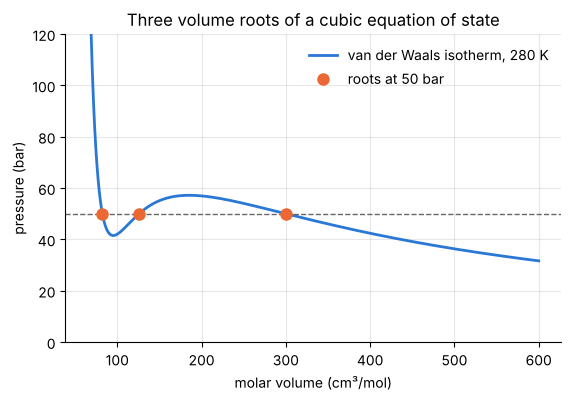

In [11]:
assert len(roots) == 3 and all(r.is_real for r in roots)
V_liq, V_mid, V_vap = [float(r) for r in roots]

Vg = np.linspace(6.5e-5, 6e-4, 400)
P_fun = sp.lambdify(V, P_vdw.subs({k: co2[k] for k in (a, b, R, T)}), "numpy")

fig, ax = plt.subplots()
ax.plot(Vg * 1e6, P_fun(Vg) / 1e5, label="van der Waals isotherm, 280 K")
ax.axhline(50, color="0.4", lw=1, ls="--")
ax.plot(np.array([V_liq, V_mid, V_vap]) * 1e6, [50] * 3, "o", color="#eb6834", ms=8, label="roots at 50 bar")
ax.set(xlabel="molar volume (cm³/mol)", ylabel="pressure (bar)", ylim=(0, 120),
       title="Three volume roots of a cubic equation of state")
ax.legend(frameon=False);

## 2.5 When there is no closed form: `nsolve` and the Colebrook equation

**Problem.** The Darcy friction factor $f$ for turbulent pipe flow satisfies

$$\frac{1}{\sqrt f} = -2\log_{10}\!\left(\frac{\varepsilon/D}{3.7} + \frac{2.51}{Re\sqrt f}\right)$$

The unknown appears on both sides. `nsolve` finds the root numerically from a starting guess.

A practical tip: solve for $X = 1/\sqrt f$ instead of $f$. The equation is then almost linear
in $X$, and the iteration converges from any reasonable guess.

In [12]:
X, Re, eps_r = sp.symbols("X Re epsilon_r", positive=True)
colebrook = sp.Eq(X, -2 * sp.log(eps_r / sp.Rational(37, 10) + sp.Rational(251, 100) * X / Re, 10))
colebrook

          ⎛10⋅εᵣ   251⋅X ⎞ 
    -2⋅log⎜───── + ──────⎟ 
          ⎝ 37     100⋅Re⎠ 
X = ───────────────────────
            log(10)        

In [13]:
def friction_factor(reynolds, rel_roughness):
    """Darcy friction factor from the Colebrook equation."""
    X_num = sp.nsolve(colebrook.subs({Re: reynolds, eps_r: rel_roughness}), X, 7)
    return float(1 / X_num**2)

f_num = friction_factor(1e5, 1e-4)
f_num

0.01851386607747164

**Verify** against the explicit Haaland correlation, which approximates Colebrook to within
about 2 %.

In [14]:
haaland = (-1.8 * np.log10((1e-4 / 3.7) ** 1.11 + 6.9 / 1e5)) ** -2
print(f"Colebrook {f_num:.5f}   Haaland {haaland:.5f}   difference {abs(f_num / haaland - 1):.2%}")
assert abs(f_num / haaland - 1) < 0.02

Colebrook 0.01851   Haaland 0.01827   difference 1.36%


Repeating the solve over a range of Reynolds numbers draws the turbulent part of the Moody chart.

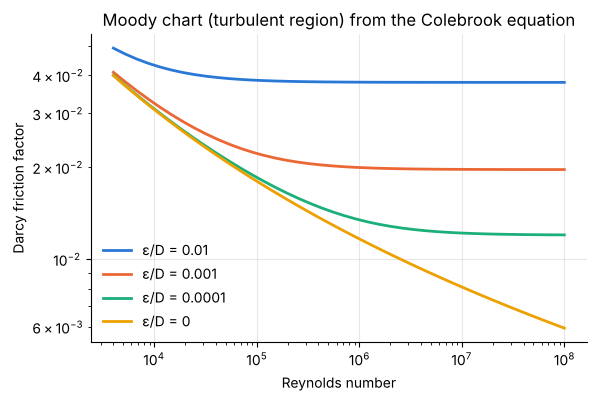

In [15]:
Re_grid = np.logspace(np.log10(4e3), 8, 40)
fig, ax = plt.subplots()
for rr in (0.01, 1e-3, 1e-4, 0):
    ax.loglog(Re_grid, [friction_factor(r, rr) for r in Re_grid], label=f"ε/D = {rr:g}")
ax.set(xlabel="Reynolds number", ylabel="Darcy friction factor",
       title="Moody chart (turbulent region) from the Colebrook equation")
ax.legend(frameon=False);

## 2.6 `solveset`: every solution, stated precisely

`solve` returns a few representative solutions. `solveset` returns a mathematical set, which can
be infinite. Resonance conditions and standing waves are typical cases.

In [16]:
sp.solveset(sp.sin(x), x, domain=sp.S.Reals)

{2⋅n⋅π │ n ∊ ℤ} ∪ {2⋅n⋅π + π │ n ∊ ℤ}

In [17]:
# restrict the domain to get a finite list
sp.solveset(sp.sin(x), x, domain=sp.Interval(0, 2 * sp.pi))

{0, π, 2⋅π}

## Exercises

1. A mixer combines streams of 10 %, 30 % and 60 % acid to make 100 kg of 35 % acid, using twice
   as much of the 30 % stream as the 10 % stream. Set up and solve the three balances.
2. Repeat 2.3 for the Redlich–Kwong equation $P = \dfrac{RT}{V-b} - \dfrac{a}{\sqrt{T}\,V(V+b)}$.
   `solve` may struggle: substitute $V = \xi b$, solve the first condition for $a$, substitute
   into the second to get a cubic in $\xi$, and solve that numerically. Check that $Z_c = 1/3$.
3. Raise the temperature in 2.4 to 320 K (above $T_c$). How many real roots remain?
   Use `[r for r in roots if r.is_real]`.
4. For $Re = 10^6$, how rough must a pipe be before $f$ exceeds 0.02? Write the original
   Colebrook equation with $f = 0.02$ and solve for $\varepsilon/D$. The unknown now appears
   only once, so `sp.solve` finds a closed form. (Answer: about $1.0\times10^{-3}$.)